# 03 – Multi-model (weekday-specific) daily MSW forecasting


## 1. Setup

In [1]:
# Run once if these packages are missing
%pip install lightgbm prophet statsforecast


[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: C:\Users\Dell User\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip


In [2]:
import os
import random
import logging
import traceback
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
import lightgbm as lgb
from statsforecast.models import AutoARIMA
from prophet import Prophet

warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").setLevel(logging.WARNING)
logging.getLogger("prophet").setLevel(logging.WARNING)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

Importing plotly failed. Interactive plots will not work.


In [6]:
# ---------------- Configuration ----------------
DATA_DIR = "../processed_datasets/outputs"
DATASETS = {
    "Moratuwa":      "daily_waste_output_Moratuwa_datefixed.csv",
    "Dehiwala":      "daily_waste_output_Dehiwala_datefixed.csv",
    "Boralasgamuwa": "daily_waste_output_Boralasgamuwa_datefixed.csv",
    "Ballarat":      "daily_waste_output_Ballarat_datefixed.csv",
    "Austin":        "daily_waste_output_Austin_datefixed.csv",    
}

TEST_RATIO = 0.30
N_VAL_FOLDS = 3
VAL_FRACTION = 0.10
MIN_VAL_OBS = 3               # smallest validation block 
MIN_REAL_TRAIN = 20           # smallest number of real training targets for a weekday model
LAG_GRID_WEEKS = [2, 4, 8]    # lags in weeks = previous values of the same weekday
PRIMARY_METRIC = "RMSE"
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

OUTPUT_DIR = "results_multi"
SINGLE_MODEL_METRICS = "results/metrics_all.csv"    
os.makedirs(OUTPUT_DIR, exist_ok=True)

## 2. Data loading, split and weekday extraction

In [7]:
def load_dataset(name, file_name):
    """Load one preprocessed dataset as a continuous daily series (identical to 02).

    Returns a DataFrame indexed by date with y (kg) and scored (True = real recorded day).
    """
    path = os.path.join(DATA_DIR, file_name)
    if not os.path.exists(path):
        raise FileNotFoundError(f"{path} not found – run pre_files/{name.lower()}.ipynb first")

    df = pd.read_csv(path)
    df["ticket_date"] = pd.to_datetime(df["ticket_date"], utc=True).dt.tz_localize(None).dt.normalize()
    df = df.sort_values("ticket_date").set_index("ticket_date")
    if df.index.duplicated().any():
        raise ValueError(f"{name}: duplicate dates in {file_name}")
    full = pd.date_range(df.index.min(), df.index.max(), freq="D")
    if len(full) != len(df):
        raise ValueError(f"{name}: series is not continuous ({len(full) - len(df)} calendar days missing)")
    if df["net_weight_kg"].isna().any():
        raise ValueError(f"{name}: net_weight_kg still has blanks – preprocessing incomplete")

    out = pd.DataFrame(index=full)
    out["y"] = df["net_weight_kg"].astype(float)
    not_real = pd.Series(False, index=full)
    for flag in ["is_imputed", "is_closure_zero"]:
        if flag in df.columns:
            not_real |= df[flag].astype(bool)
    out["scored"] = ~not_real
    return out


def split_date(d, test_ratio=TEST_RATIO):
    """First test date: the same 70/30 cut of the daily series as in 02."""
    return d.index[int(round(len(d) * (1 - test_ratio)))]


def weekday_series(d, dow, first_test_date):
    """Chronological series of one weekday (0 = Monday) and the number of its training observations."""
    w = d[d.index.dayofweek == dow]
    n_train = int((w.index < first_test_date).sum())
    return w["y"], w["scored"], n_train


def validation_folds(n_train, n_folds=N_VAL_FOLDS, val_fraction=VAL_FRACTION):
    """Expanding-window folds inside the training part: (val_start, val_end) positions."""
    size = max(int(n_train * val_fraction), MIN_VAL_OBS)
    return [(n_train - k * size, n_train - (k - 1) * size) for k in range(n_folds, 0, -1)
            if n_train - k * size > 0]


class WeekdayModelError(Exception):
    """Raised when one weekday model cannot be trained or used."""

In [8]:
data = {}
for name, file_name in DATASETS.items():
    try:
        data[name] = load_dataset(name, file_name)
    except Exception as e:
        print(f"[FAILED] dataset={name} step=data loading: {type(e).__name__}: {e}")
if not data:
    raise RuntimeError(f"No dataset could be loaded from {DATA_DIR} – run the pre_files notebooks first")

rows = []
for name, d in data.items():
    cut = split_date(d)
    for dow, day in enumerate(WEEKDAYS):
        y, scored, n_train = weekday_series(d, dow, cut)
        rows.append({"dataset": name, "weekday": day, "train_obs": n_train, "test_obs": len(y) - n_train,
                     "train_share_%": round(n_train / len(y) * 100, 1),
                     "real_train_targets": int(scored.iloc[:n_train].sum()),
                     "real_test_days": int(scored.iloc[n_train:].sum()),
                     "train_median_kg": float(y.iloc[:n_train].median())})
weekday_overview = pd.DataFrame(rows)
weekday_overview.to_csv(os.path.join(OUTPUT_DIR, "weekday_series_overview.csv"), index=False)
weekday_overview

,dataset,weekday,train_obs,test_obs,train_share_%,real_train_targets,real_test_days,train_median_kg
0,Moratuwa,Monday,146,63,69.9,146,63,8.103250e+04
1,Moratuwa,Tuesday,146,62,70.2,146,62,7.862721e+04
2,Moratuwa,Wednesday,146,62,70.2,146,62,7.563500e+04
3,Moratuwa,Thursday,147,62,70.3,147,62,7.584000e+04
4,Moratuwa,Friday,146,63,69.9,146,63,7.591000e+04
5,Moratuwa,Saturday,146,63,69.9,146,63,1.111242e+05
6,Moratuwa,Sunday,146,63,69.9,146,63,9.705000e+04
7,Dehiwala,Monday,146,63,69.9,146,63,1.512650e+05
8,Dehiwala,Tuesday,146,63,69.9,146,63,1.570200e+05
9,Dehiwala,Wednesday,146,63,69.9,146,63,1.502600e+05


## 3. Metrics 

In [9]:
def compute_metrics(actual, predicted):
    """MAE, RMSE and MAPE. Zero actual values are excluded from MAPE only (reported separately)."""
    a = np.asarray(actual, dtype=float)
    p = np.asarray(predicted, dtype=float)
    err = a - p
    nonzero = a != 0
    return {
        "MAE": float(np.mean(np.abs(err))) if len(a) else np.nan,
        "RMSE": float(np.sqrt(np.mean(err ** 2))) if len(a) else np.nan,
        "MAPE_%": float(np.mean(np.abs(err[nonzero] / a[nonzero])) * 100) if nonzero.any() else np.nan,
        "n_scored": int(len(a)),
        "n_zero_excluded_from_MAPE": int((~nonzero).sum()),
    }


def rmse(actual, predicted):
    return float(np.sqrt(np.mean((np.asarray(actual, float) - np.asarray(predicted, float)) ** 2)))

## 4. Lag features for a weekday series


In [10]:
def make_lag_features(y, n_lags):
    """Lag matrix from past values only: lag_k = value k steps (weeks) earlier."""
    return pd.concat({f"lag_{k}": y.shift(k) for k in range(1, n_lags + 1)}, axis=1)

## 5. Model functions (one weekday series at a time)


In [11]:
def tune_and_fit_lag_model(build_model, grid, y, scored, n_train):
    """Shared routine for the lag-feature regressors on one weekday series.

    Lag settings that leave fewer than MIN_REAL_TRAIN real training targets are skipped (insufficient history).
    Hyperparameters are chosen by expanding-window CV inside the training part (RMSE on real days).
    """
    positions = np.arange(len(y))
    cv_rows = []
    for params in grid:
        X = make_lag_features(y, params["lags"])
        usable = X.notna().all(axis=1).to_numpy() & scored.to_numpy()
        if (usable & (positions < n_train)).sum() < MIN_REAL_TRAIN:
            continue                                           # not enough history for this many lags
        fold_errors = []
        for val_start, val_end in validation_folds(n_train):
            tr = usable & (positions < val_start)
            va = usable & (positions >= val_start) & (positions < val_end)
            if tr.sum() < MIN_REAL_TRAIN // 2 or va.sum() == 0:
                continue
            model = build_model(params)
            model.fit(X[tr], y[tr])
            fold_errors.append(rmse(y[va], model.predict(X[va])))
        if fold_errors:
            cv_rows.append({**params, "cv_rmse": float(np.mean(fold_errors)), "folds_used": len(fold_errors)})

    if not cv_rows:
        raise WeekdayModelError(f"insufficient history: no lag setting in {LAG_GRID_WEEKS} has "
                                f"{MIN_REAL_TRAIN} real training targets and a usable validation fold")
    cv_table = pd.DataFrame(cv_rows).sort_values("cv_rmse").reset_index(drop=True)
    best = {k: v for k, v in cv_table.iloc[0].to_dict().items() if k not in ("cv_rmse", "folds_used")}
    best = {k: (int(v) if isinstance(v, float) and float(v).is_integer() else v) for k, v in best.items()}

    X = make_lag_features(y, best["lags"])
    usable = X.notna().all(axis=1).to_numpy() & scored.to_numpy()
    model = build_model(best)
    model.fit(X[usable & (positions < n_train)], y[usable & (positions < n_train)])
    test_X = X.iloc[n_train:]
    if test_X.isna().any().any():
        raise WeekdayModelError("test inputs have missing lags")
    return pd.Series(model.predict(test_X), index=test_X.index), best, cv_table


def run_linear_regression(y, scored, n_train):
    grid = [{"lags": l} for l in LAG_GRID_WEEKS]
    return tune_and_fit_lag_model(lambda p: LinearRegression(), grid, y, scored, n_train)


def run_random_forest(y, scored, n_train):
    grid = [{"lags": l, "max_depth": d, "min_samples_leaf": m}
            for l in LAG_GRID_WEEKS for d in [4, 8] for m in [1, 3]]
    build = lambda p: RandomForestRegressor(n_estimators=200, max_depth=int(p["max_depth"]),
                                            min_samples_leaf=int(p["min_samples_leaf"]),
                                            random_state=SEED, n_jobs=-1)
    return tune_and_fit_lag_model(build, grid, y, scored, n_train)


def run_lightgbm(y, scored, n_train):

    grid = [{"lags": l, "num_leaves": nl, "learning_rate": lr}
            for l in LAG_GRID_WEEKS for nl in [7, 15] for lr in [0.03, 0.1]]
    build = lambda p: lgb.LGBMRegressor(n_estimators=300, num_leaves=int(p["num_leaves"]),
                                        learning_rate=float(p["learning_rate"]), min_child_samples=5,
                                        subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                        random_state=SEED, deterministic=True, verbose=-1)
    return tune_and_fit_lag_model(build, grid, y, scored, n_train)

In [12]:
def run_auto_arima(y, scored, n_train):
    """Auto ARIMA on one weekday series.

    Non-seasonal (season_length=1): the weekly pattern is already removed by the weekday split, and a yearly
    season would be 52 steps, too long for about 150 training weeks. Orders and coefficients come from the
    training part only. 'fitted' values of the full series give one-step-ahead forecasts (previous weeks only).
    """
    if n_train < MIN_REAL_TRAIN:
        raise WeekdayModelError(f"insufficient history: {n_train} training weeks < {MIN_REAL_TRAIN}")
    model = AutoARIMA(season_length=1)
    model.fit(y.iloc[:n_train].to_numpy(dtype=float))
    out = model.forward(y=y.to_numpy(dtype=float), h=1, fitted=True)
    fitted = np.asarray(out["fitted"], dtype=float)
    try:
        from statsforecast.arima import arima_string
        order = arima_string(model.model_)
    except Exception:
        order = "see model.model_"
    return (pd.Series(fitted[n_train:], index=y.index[n_train:]), {"model": order},
            pd.DataFrame([{"selection": "AICc on training data", "model": order}]))


def run_prophet(y, scored, n_train):
    """Prophet on one weekday series: columns 'ds' and 'y', no weekly seasonality (one weekday only),
    yearly seasonality kept. Non-real days are NaN and skipped by Prophet. Tuned on training folds."""
    frame = pd.DataFrame({"ds": y.index, "y": y.where(scored).to_numpy()})
    if frame["y"].iloc[:n_train].notna().sum() < MIN_REAL_TRAIN:
        raise WeekdayModelError(f"insufficient history: fewer than {MIN_REAL_TRAIN} real training values")

    def fit_predict(train_frame, future_dates, params):
        m = Prophet(weekly_seasonality=False, yearly_seasonality=True, daily_seasonality=False,
                    changepoint_prior_scale=params["changepoint_prior_scale"],
                    seasonality_mode=params["seasonality_mode"])
        m.fit(train_frame)
        return m.predict(pd.DataFrame({"ds": future_dates}))["yhat"].to_numpy()

    grid = [{"changepoint_prior_scale": c, "seasonality_mode": s}
            for c in [0.01, 0.1, 0.5] for s in ["additive", "multiplicative"]]
    cv_rows = []
    for params in grid:
        fold_errors = []
        for val_start, val_end in validation_folds(n_train):
            mask = scored.iloc[val_start:val_end].to_numpy()
            if frame["y"].iloc[:val_start].notna().sum() < MIN_REAL_TRAIN // 2 or not mask.any():
                continue
            pred = fit_predict(frame.iloc[:val_start], frame["ds"].iloc[val_start:val_end], params)
            fold_errors.append(rmse(y.iloc[val_start:val_end][mask], pred[mask]))
        if fold_errors:
            cv_rows.append({**params, "cv_rmse": float(np.mean(fold_errors)), "folds_used": len(fold_errors)})
    if not cv_rows:
        raise WeekdayModelError("no usable validation fold for Prophet")
    cv_table = pd.DataFrame(cv_rows).sort_values("cv_rmse").reset_index(drop=True)
    best = {k: v for k, v in cv_table.iloc[0].to_dict().items() if k not in ("cv_rmse", "folds_used")}
    pred = fit_predict(frame.iloc[:n_train], frame["ds"].iloc[n_train:], best)
    return pd.Series(pred, index=y.index[n_train:]), best, cv_table


def run_seasonal_naive(y, scored, n_train):
    """Reference (not ranked): previous value of the same weekday, identical to the 02 reference."""
    return y.shift(1).iloc[n_train:], {"rule": "same weekday last week"}, pd.DataFrame()


MODELS = {
    "Multiple Linear Regression": run_linear_regression,
    "Auto ARIMA": run_auto_arima,
    "LightGBM": run_lightgbm,
    "Random Forest": run_random_forest,
    "Prophet": run_prophet,
}
REFERENCE = {"Seasonal naive (reference)": run_seasonal_naive}

## 6. Weekday-specific training and reconstruction

In [13]:
def is_closed_weekday(y, scored, n_train):
    """Closure weekday with too few real values to train on (e.g. Ballarat Sunday)."""
    return (y.iloc[:n_train].median() == 0) and (scored.iloc[:n_train].sum() < MIN_REAL_TRAIN)


def run_weekday_approach(d, run_model):
    cut = split_date(d)
    parts, status, cv_tables = [], [], {}
    for dow, day in enumerate(WEEKDAYS):
        y, scored, n_train = weekday_series(d, dow, cut)
        info = {"weekday": day, "train_obs": n_train, "test_obs": len(y) - n_train,
                "real_train_targets": int(scored.iloc[:n_train].sum())}
        if is_closed_weekday(y, scored, n_train):
            pred = pd.Series(0.0, index=y.index[n_train:])
            info.update(status="closed weekday: predicted 0", params="")
        else:
            try:
                pred, params, cv = run_model(y, scored, n_train)
            except Exception as e:
                raise WeekdayModelError(f"weekday={day}: {type(e).__name__}: {e}") from e
            info.update(status="model", params=str(params))
            cv_tables[day] = cv
        pred = pred.reindex(y.index[n_train:])
        if pred.isna().any():
            raise WeekdayModelError(f"weekday={day}: {int(pred.isna().sum())} test days have no prediction")
        parts.append(pd.DataFrame({"weekday": day, "actual": y.iloc[n_train:], "predicted": pred.clip(lower=0),
                                   "scored": scored.iloc[n_train:]}))
        status.append(info)

    combined = pd.concat(parts).sort_index()          # restore chronological order
    combined.index.name = "date"
    expected = d.index[d.index >= cut]
    if not combined.index.equals(expected):
        raise WeekdayModelError("reconstructed daily series does not match the test period")
    return combined, pd.DataFrame(status), cv_tables

## 7. Run every dataset × algorithm

In [14]:
def safe_name(text):
    return "".join(c if c.isalnum() else "_" for c in text).strip("_")


def plot_combined(dataset, model_name, combined, path):
    fig, ax = plt.subplots(figsize=(16, 5))
    ax.plot(combined.index, combined["actual"].where(combined["scored"]), lw=1, color="black", label="actual (real days)")
    ax.plot(combined.index, combined["predicted"], lw=1, color="tab:green", alpha=0.85, label="predicted (7 weekday models)")
    ax.set_title(f"{dataset} – {model_name} (weekday-specific): combined daily forecast")
    ax.set_ylabel("kg"); ax.legend(); ax.grid(alpha=0.3)
    fig.tight_layout(); fig.savefig(path, dpi=120); plt.close(fig)


def plot_by_weekday(dataset, model_name, combined, path):
    fig, axes = plt.subplots(7, 1, figsize=(14, 16), sharex=True)
    for ax, day in zip(axes, WEEKDAYS):
        part = combined[combined["weekday"] == day]
        ax.plot(part.index, part["actual"].where(part["scored"]), color="black", lw=1, marker=".", label="actual")
        ax.plot(part.index, part["predicted"], color="tab:green", lw=1, marker=".", label="predicted")
        ax.set_ylabel(day[:3]); ax.grid(alpha=0.3)
    axes[0].legend(loc="upper right"); axes[0].set_title(f"{dataset} – {model_name}: weekday models")
    fig.tight_layout(); fig.savefig(path, dpi=110); plt.close(fig)


metrics_rows, weekday_metric_rows, status_rows, errors, all_combined = [], [], [], [], {}

for dataset, d in data.items():
    out_dir = os.path.join(OUTPUT_DIR, safe_name(dataset))
    os.makedirs(out_dir, exist_ok=True)
    for model_name, run_model in {**MODELS, **REFERENCE}.items():
        print(f"Running dataset={dataset} model={model_name} (7 weekday models) ...", flush=True)
        try:
            combined, status, cv_tables = run_weekday_approach(d, run_model)
        except Exception as e:
            errors.append({"dataset": dataset, "model": model_name, "error": f"{type(e).__name__}: {e}",
                           "traceback": traceback.format_exc()})
            print(f"[FAILED] dataset={dataset} model={model_name}: {type(e).__name__}: {e}")
            continue

        tag = safe_name(model_name)
        s = combined[combined["scored"]]
        m = compute_metrics(s["actual"], s["predicted"])
        closed = status.loc[status["status"] != "model", "weekday"].tolist()
        metrics_rows.append({"dataset": dataset, "model": model_name, **m,
                             "closed_weekdays_predicted_0": ", ".join(closed)})
        for day, part in s.groupby("weekday"):
            weekday_metric_rows.append({"dataset": dataset, "model": model_name, "weekday": day,
                                        **compute_metrics(part["actual"], part["predicted"])})
        status_rows.append(status.assign(dataset=dataset, model=model_name))
        all_combined[(dataset, model_name)] = combined

        # weekday-specific predictions (grouped by weekday) and combined daily predictions (chronological)
        by_weekday = combined.reset_index()
        by_weekday["weekday_order"] = by_weekday["weekday"].map(WEEKDAYS.index)
        by_weekday.sort_values(["weekday_order", "date"]).drop(columns="weekday_order") \
                  .to_csv(os.path.join(out_dir, f"weekday_predictions_{tag}.csv"), index=False)
        combined.to_csv(os.path.join(out_dir, f"combined_predictions_{tag}.csv"))
        status.to_csv(os.path.join(out_dir, f"weekday_status_{tag}.csv"), index=False)
        for day, cv in cv_tables.items():
            if len(cv):
                cv.to_csv(os.path.join(out_dir, f"validation_{tag}_{day}.csv"), index=False)
        plot_combined(dataset, model_name, combined, os.path.join(out_dir, f"plot_combined_{tag}.png"))
        plot_by_weekday(dataset, model_name, combined, os.path.join(out_dir, f"plot_weekdays_{tag}.png"))
        note = f" | closed weekdays predicted 0: {closed}" if closed else ""
        print(f"   done: RMSE {m['RMSE']:,.0f} | MAE {m['MAE']:,.0f} | MAPE {m['MAPE_%']:.2f} %{note}")

print(f"\nFinished: {len(metrics_rows)} successful runs, {len(errors)} failures")
if errors:
    print("FAILED combinations (no metrics were produced for these):")
    display(pd.DataFrame(errors)[["dataset", "model", "error"]])
    pd.DataFrame(errors).to_csv(os.path.join(OUTPUT_DIR, "errors.csv"), index=False)

Running dataset=Moratuwa model=Multiple Linear Regression (7 weekday models) ...
   done: RMSE 19,334 | MAE 13,926 | MAPE 20.71 %
Running dataset=Moratuwa model=Auto ARIMA (7 weekday models) ...
   done: RMSE 19,535 | MAE 14,371 | MAPE 21.14 %
Running dataset=Moratuwa model=LightGBM (7 weekday models) ...
   done: RMSE 22,723 | MAE 17,412 | MAPE 24.99 %
Running dataset=Moratuwa model=Random Forest (7 weekday models) ...
   done: RMSE 20,016 | MAE 14,670 | MAPE 21.95 %
Running dataset=Moratuwa model=Prophet (7 weekday models) ...


Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
15:08:13 - cmdstanpy - INFO - Chain [1] start processing
15:08:15 - cmdstanpy - INFO - Chain [1] done processing
15:08:19 - cmdstanpy - INFO - Chain [1] start processing
15:08:20 - cmdstanpy - INFO - Chain [1] done processing
15:08:20 - cmdstanpy - INFO - Chain [1] start processing
15:08:21 - cmdstanpy - INFO - Chain [1] done processing
Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
15:08:21 - cmdstanpy - INFO - Chain [1] start processing
15:08:22 - cmdstanpy - INF

   done: RMSE 30,760 | MAE 21,642 | MAPE 33.03 %
Running dataset=Moratuwa model=Seasonal naive (reference) (7 weekday models) ...
   done: RMSE 22,391 | MAE 16,418 | MAPE 22.89 %
Running dataset=Dehiwala model=Multiple Linear Regression (7 weekday models) ...
   done: RMSE 31,165 | MAE 21,998 | MAPE 20.93 %
Running dataset=Dehiwala model=Auto ARIMA (7 weekday models) ...
   done: RMSE 31,252 | MAE 21,474 | MAPE 21.52 %
Running dataset=Dehiwala model=LightGBM (7 weekday models) ...
   done: RMSE 31,707 | MAE 22,620 | MAPE 21.60 %
Running dataset=Dehiwala model=Random Forest (7 weekday models) ...
   done: RMSE 30,599 | MAE 21,500 | MAPE 20.85 %
Running dataset=Dehiwala model=Prophet (7 weekday models) ...


Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
15:16:24 - cmdstanpy - INFO - Chain [1] start processing
15:16:25 - cmdstanpy - INFO - Chain [1] done processing
15:16:26 - cmdstanpy - INFO - Chain [1] start processing
15:16:26 - cmdstanpy - INFO - Chain [1] done processing
15:16:27 - cmdstanpy - INFO - Chain [1] start processing
15:16:27 - cmdstanpy - INFO - Chain [1] done processing
Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
15:16:27 - cmdstanpy - INFO - Chain [1] start processing
15:16:28 - cmdstanpy - INF

   done: RMSE 33,674 | MAE 22,737 | MAPE 24.14 %
Running dataset=Dehiwala model=Seasonal naive (reference) (7 weekday models) ...
   done: RMSE 36,621 | MAE 24,450 | MAPE 22.62 %
Running dataset=Boralasgamuwa model=Multiple Linear Regression (7 weekday models) ...
   done: RMSE 6,377 | MAE 4,734 | MAPE 20.49 %
Running dataset=Boralasgamuwa model=Auto ARIMA (7 weekday models) ...
   done: RMSE 6,401 | MAE 4,753 | MAPE 20.83 %
Running dataset=Boralasgamuwa model=LightGBM (7 weekday models) ...
   done: RMSE 7,055 | MAE 5,338 | MAPE 23.25 %
Running dataset=Boralasgamuwa model=Random Forest (7 weekday models) ...
   done: RMSE 6,459 | MAE 4,814 | MAPE 21.15 %
Running dataset=Boralasgamuwa model=Prophet (7 weekday models) ...


...

   done: RMSE 9,809 | MAE 7,759 | MAPE 30.03 %
Running dataset=Boralasgamuwa model=Seasonal naive (reference) (7 weekday models) ...
   done: RMSE 8,393 | MAE 6,273 | MAPE 26.73 %
Running dataset=Ballarat model=Multiple Linear Regression (7 weekday models) ...
   done: RMSE 7,787 | MAE 4,494 | MAPE 7.31 %
Running dataset=Ballarat model=Auto ARIMA (7 weekday models) ...
   done: RMSE 7,728 | MAE 4,515 | MAPE 7.19 %
Running dataset=Ballarat model=LightGBM (7 weekday models) ...
   done: RMSE 8,243 | MAE 4,832 | MAPE 7.83 %
Running dataset=Ballarat model=Random Forest (7 weekday models) ...
   done: RMSE 8,150 | MAE 4,782 | MAPE 7.73 %
Running dataset=Ballarat model=Prophet (7 weekday models) ...


15:45:32 - cmdstanpy - INFO - Chain [1] start processing
15:45:35 - cmdstanpy - INFO - Chain [1] done processing
15:45:36 - cmdstanpy - INFO - Chain [1] start processing
15:45:38 - cmdstanpy - INFO - Chain [1] done processing
15:45:38 - cmdstanpy - INFO - Chain [1] start processing
15:45:40 - cmdstanpy - INFO - Chain [1] done processing
15:45:40 - cmdstanpy - INFO - Chain [1] start processing
15:45:41 - cmdstanpy - INFO - Chain [1] done processing
15:45:42 - cmdstanpy - INFO - Chain [1] start processing
15:45:43 - cmdstanpy - INFO - Chain [1] done processing
15:45:43 - cmdstanpy - INFO - Chain [1] start processing
15:45:44 - cmdstanpy - INFO - Chain [1] done processing
15:45:45 - cmdstanpy - INFO - Chain [1] start processing
15:45:46 - cmdstanpy - INFO - Chain [1] done processing
15:45:47 - cmdstanpy - INFO - Chain [1] start processing
15:45:48 - cmdstanpy - INFO - Chain [1] done processing
15:45:49 - cmdstanpy - INFO - Chain [1] start processing
15:45:49 - cmdstanpy - INFO - Chain [1]

   done: RMSE 10,024 | MAE 6,329 | MAPE 10.18 %
Running dataset=Ballarat model=Seasonal naive (reference) (7 weekday models) ...
   done: RMSE 8,377 | MAE 4,071 | MAPE 7.20 %
Running dataset=Austin model=Multiple Linear Regression (7 weekday models) ...
   done: RMSE 181,103 | MAE 89,833 | MAPE 39.49 %
Running dataset=Austin model=Auto ARIMA (7 weekday models) ...
   done: RMSE 177,104 | MAE 90,783 | MAPE 44.30 %
Running dataset=Austin model=LightGBM (7 weekday models) ...
   done: RMSE 195,941 | MAE 103,349 | MAPE 37.96 %
Running dataset=Austin model=Random Forest (7 weekday models) ...
   done: RMSE 182,732 | MAE 91,747 | MAPE 29.56 %
Running dataset=Austin model=Prophet (7 weekday models) ...


15:55:44 - cmdstanpy - INFO - Chain [1] start processing
15:55:48 - cmdstanpy - INFO - Chain [1] done processing
15:55:50 - cmdstanpy - INFO - Chain [1] start processing
15:55:52 - cmdstanpy - INFO - Chain [1] done processing
15:55:52 - cmdstanpy - INFO - Chain [1] start processing
15:55:53 - cmdstanpy - INFO - Chain [1] done processing
15:55:53 - cmdstanpy - INFO - Chain [1] start processing
15:55:54 - cmdstanpy - INFO - Chain [1] done processing
15:55:54 - cmdstanpy - INFO - Chain [1] start processing
15:55:55 - cmdstanpy - INFO - Chain [1] done processing
15:55:55 - cmdstanpy - INFO - Chain [1] start processing
15:55:56 - cmdstanpy - INFO - Chain [1] done processing
15:55:57 - cmdstanpy - INFO - Chain [1] start processing
15:55:57 - cmdstanpy - INFO - Chain [1] done processing
15:55:59 - cmdstanpy - INFO - Chain [1] start processing
15:56:01 - cmdstanpy - INFO - Chain [1] done processing
15:56:01 - cmdstanpy - INFO - Chain [1] start processing
15:56:02 - cmdstanpy - INFO - Chain [1]

   done: RMSE 170,943 | MAE 95,296 | MAPE 114.37 %
Running dataset=Austin model=Seasonal naive (reference) (7 weekday models) ...
   done: RMSE 208,466 | MAE 94,261 | MAPE 22.62 %

Finished: 30 successful runs, 0 failures


## 8. Metrics

In [15]:
metrics = pd.DataFrame(metrics_rows)
metrics.to_csv(os.path.join(OUTPUT_DIR, "metrics_all.csv"), index=False)
display(metrics.round(2))

weekday_metrics = pd.DataFrame(weekday_metric_rows)
weekday_metrics.to_csv(os.path.join(OUTPUT_DIR, "metrics_by_weekday.csv"), index=False)

weekday_status = pd.concat(status_rows, ignore_index=True) if status_rows else pd.DataFrame()
weekday_status.to_csv(os.path.join(OUTPUT_DIR, "weekday_model_status.csv"), index=False)
print("Weekday models that were NOT trained (closed weekdays predicted 0):")
display(weekday_status[weekday_status["status"] != "model"] if len(weekday_status) else weekday_status)

,dataset,model,MAE,RMSE,MAPE_%,n_scored,n_zero_excluded_from_MAPE,closed_weekdays_predicted_0
0,Moratuwa,Multiple Linear Regression,13925.95,19333.95,20.71,438,0,
1,Moratuwa,Auto ARIMA,14371.09,19535.03,21.14,438,0,
2,Moratuwa,LightGBM,17411.97,22722.61,24.99,438,0,
3,Moratuwa,Random Forest,14669.82,20015.98,21.95,438,0,
4,Moratuwa,Prophet,21642.02,30759.61,33.03,438,0,
5,Moratuwa,Seasonal naive (reference),16417.59,22390.61,22.89,438,0,
6,Dehiwala,Multiple Linear Regression,21998.32,31164.60,20.93,438,0,
7,Dehiwala,Auto ARIMA,21473.75,31252.39,21.52,438,0,
8,Dehiwala,LightGBM,22619.96,31707.33,21.60,438,0,
9,Dehiwala,Random Forest,21500.21,30599.27,20.85,438,0,


Weekday models that were NOT trained (closed weekdays predicted 0):


,weekday,train_obs,test_obs,real_train_targets,status,params,dataset,model


## 9. Ranking of the weekday-specific algorithms

In [16]:
ranked = metrics[metrics["model"].isin(MODELS)].copy()
ranked["rank"] = ranked.groupby("dataset")[PRIMARY_METRIC].rank(method="min")
rank_table = ranked.pivot(index="model", columns="dataset", values="rank")
rank_table.columns = [f"{c} rank" for c in rank_table.columns]
value_table = ranked.pivot(index="model", columns="dataset", values=PRIMARY_METRIC)
value_table.columns = [f"{c} {PRIMARY_METRIC}" for c in value_table.columns]
ranking = pd.concat([rank_table, value_table], axis=1)
ranking["mean rank"] = rank_table.mean(axis=1)
ranking = ranking.sort_values("mean rank")
ranking.to_csv(os.path.join(OUTPUT_DIR, "model_ranking.csv"))
ranking.round(2)

,Austin rank,Ballarat rank,Boralasgamuwa rank,Dehiwala rank,Moratuwa rank,Austin RMSE,Ballarat RMSE,Boralasgamuwa RMSE,Dehiwala RMSE,Moratuwa RMSE,mean rank
model,,,,,,,,,,,
Multiple Linear Regression,3.0,2.0,1.0,2.0,1.0,181103.22,7786.76,6376.60,31164.60,19333.95,1.8
Auto ARIMA,2.0,1.0,2.0,3.0,2.0,177104.48,7727.94,6400.62,31252.39,19535.03,2.0
Random Forest,4.0,3.0,3.0,1.0,3.0,182731.74,8149.61,6459.13,30599.27,20015.98,2.8
LightGBM,5.0,4.0,4.0,4.0,4.0,195940.80,8242.79,7054.51,31707.33,22722.61,4.2
Prophet,1.0,5.0,5.0,5.0,5.0,170943.02,10023.63,9809.16,33674.49,30759.61,4.2


## 10. Single model (02) vs weekday-specific multi-model (03)

In [17]:
if os.path.exists(SINGLE_MODEL_METRICS):
    single = pd.read_csv(SINGLE_MODEL_METRICS)
    both = single.merge(metrics, on=["dataset", "model"], suffixes=(" single", " multi"))
    for col in ["MAE", "RMSE", "MAPE_%"]:
        both[f"{col} change %"] = (both[f"{col} multi"] - both[f"{col} single"]) / both[f"{col} single"] * 100
    if not (both["n_scored single"] == both["n_scored multi"]).all():
        print("WARNING: scored test days differ between 02 and 03 for some rows – check the split")
    cols = ["dataset", "model", "RMSE single", "RMSE multi", "RMSE change %",
            "MAE single", "MAE multi", "MAPE_% single", "MAPE_% multi"]
    comparison = both[cols].sort_values(["dataset", "RMSE multi"])
    comparison.to_csv(os.path.join(OUTPUT_DIR, "single_vs_multi_comparison.csv"), index=False)
    display(comparison.round(2))
else:
    print(f"{SINGLE_MODEL_METRICS} not found – run 02_ml_single_model.ipynb first to get the comparison table")

,dataset,model,RMSE single,RMSE multi,RMSE change %,MAE single,MAE multi,MAPE_% single,MAPE_% multi
28,Austin,Prophet,188012.51,170943.02,-9.08,117347.95,95295.75,475.84,114.37
25,Austin,Auto ARIMA,169095.74,177104.48,4.74,84215.78,90783.20,116.06,44.30
24,Austin,Multiple Linear Regression,176815.00,181103.22,2.43,86072.14,89832.89,131.59,39.49
27,Austin,Random Forest,184715.80,182731.74,-1.07,88200.88,91746.93,78.49,29.56
26,Austin,LightGBM,162515.90,195940.80,20.57,82151.59,103348.78,139.30,37.96
29,Austin,Seasonal naive (reference),208466.15,208466.15,0.00,94260.76,94260.76,22.62,22.62
19,Ballarat,Auto ARIMA,7420.63,7727.94,4.14,4244.55,4515.39,7.09,7.19
18,Ballarat,Multiple Linear Regression,7754.75,7786.76,0.41,4468.60,4494.21,7.44,7.31
21,Ballarat,Random Forest,8848.92,8149.61,-7.90,5553.35,4782.31,7.12,7.73
20,Ballarat,LightGBM,9092.84,8242.79,-9.35,5977.55,4831.62,7.98,7.83


## 11. Combined forecast plots per dataset

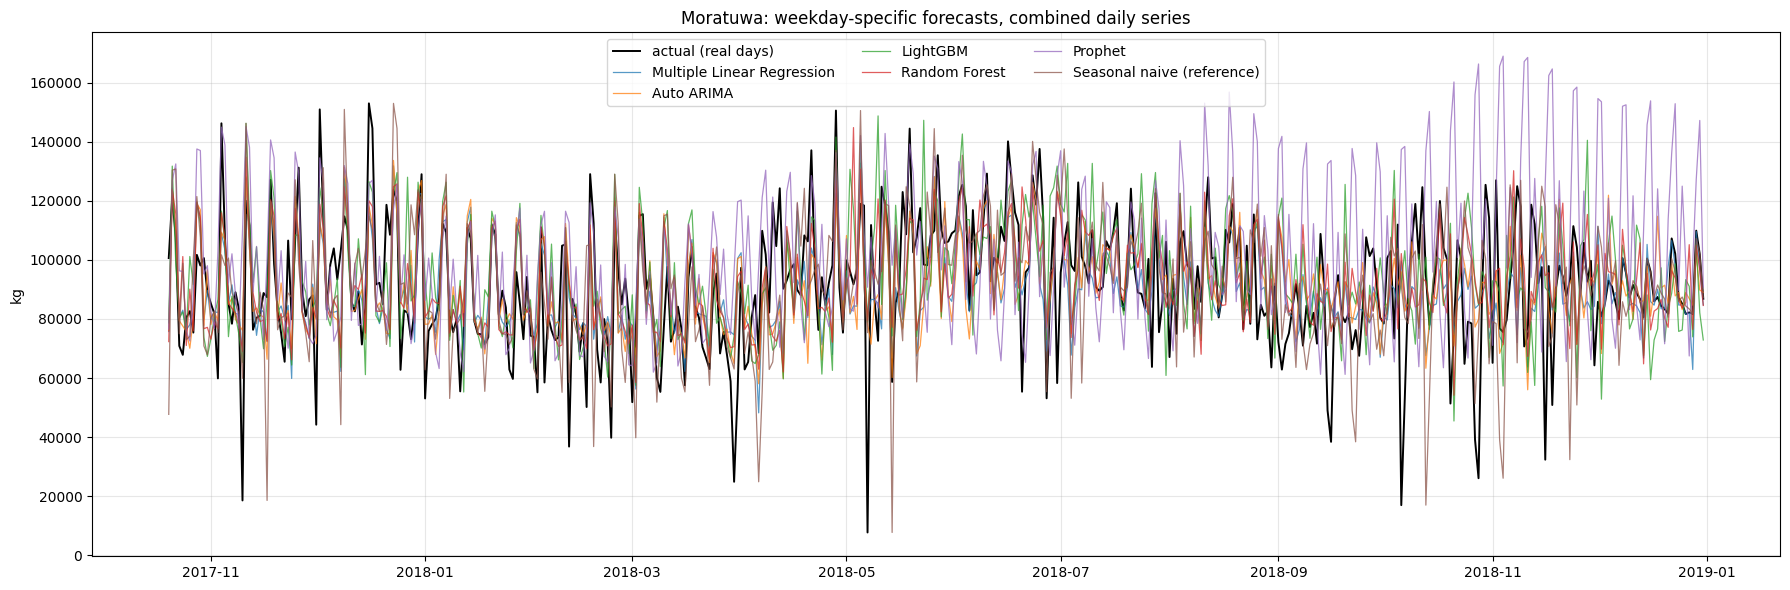

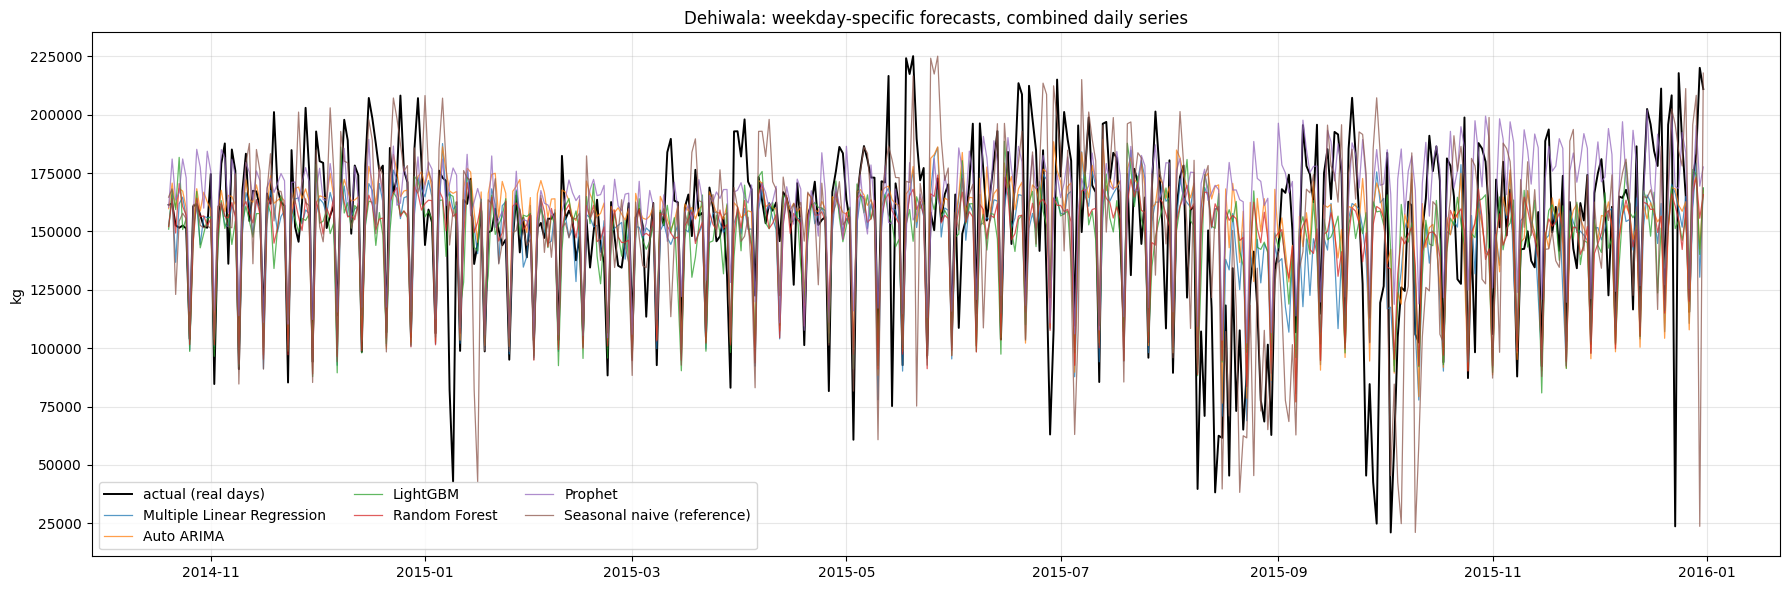

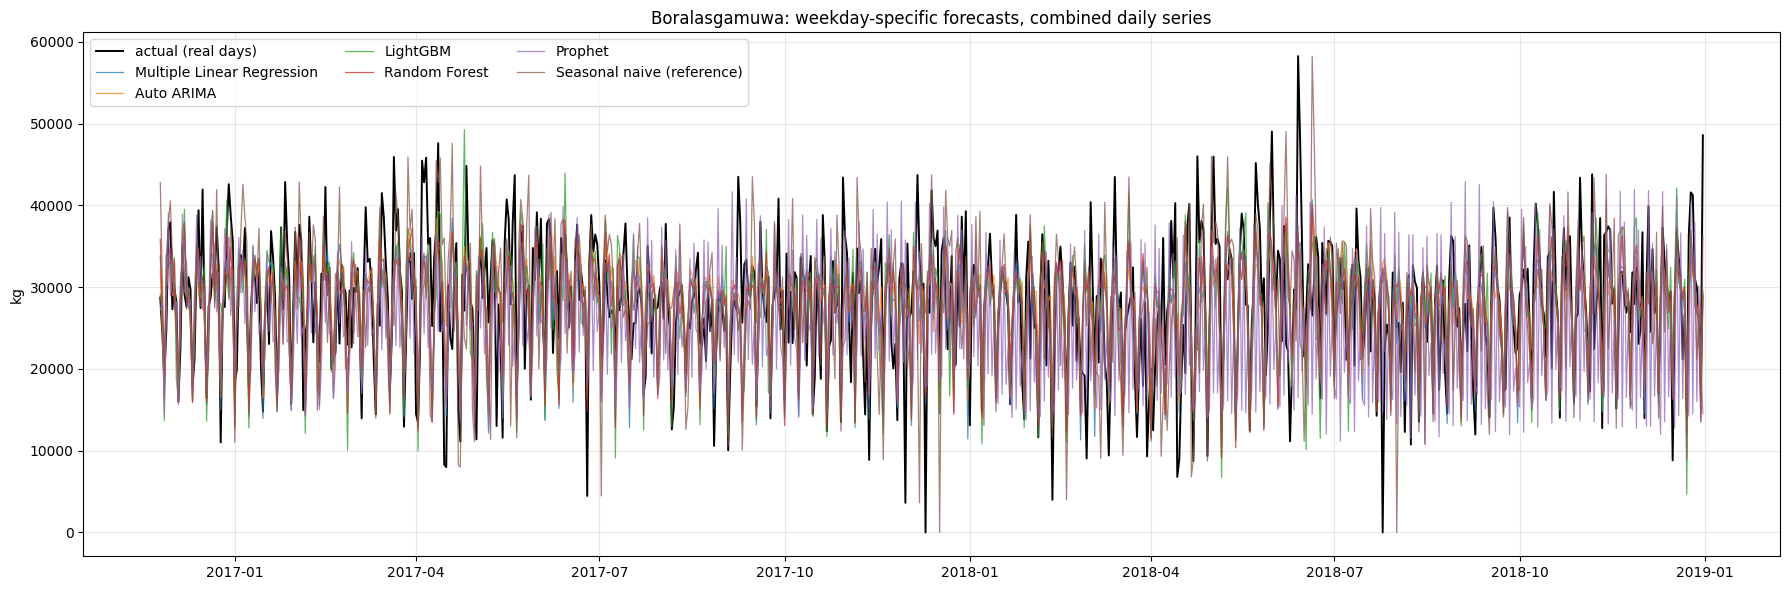

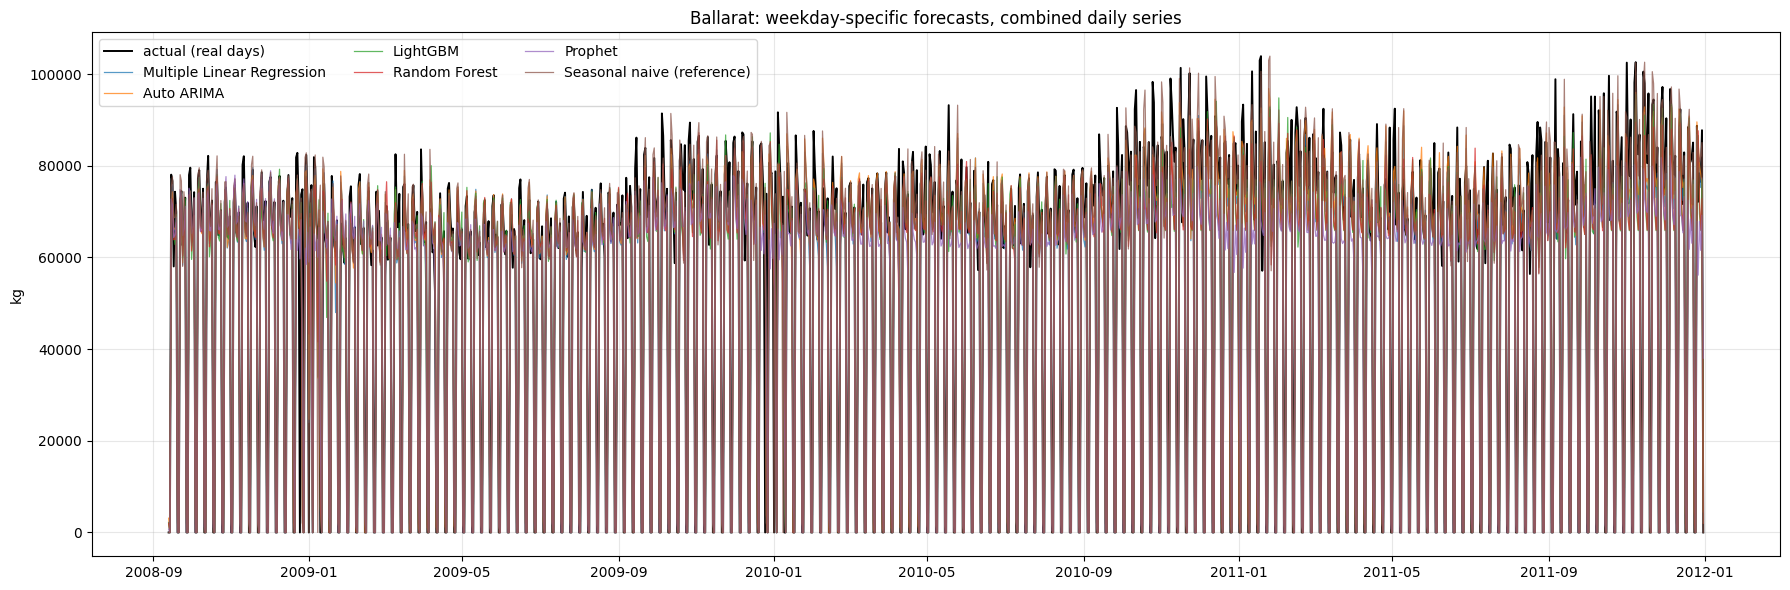

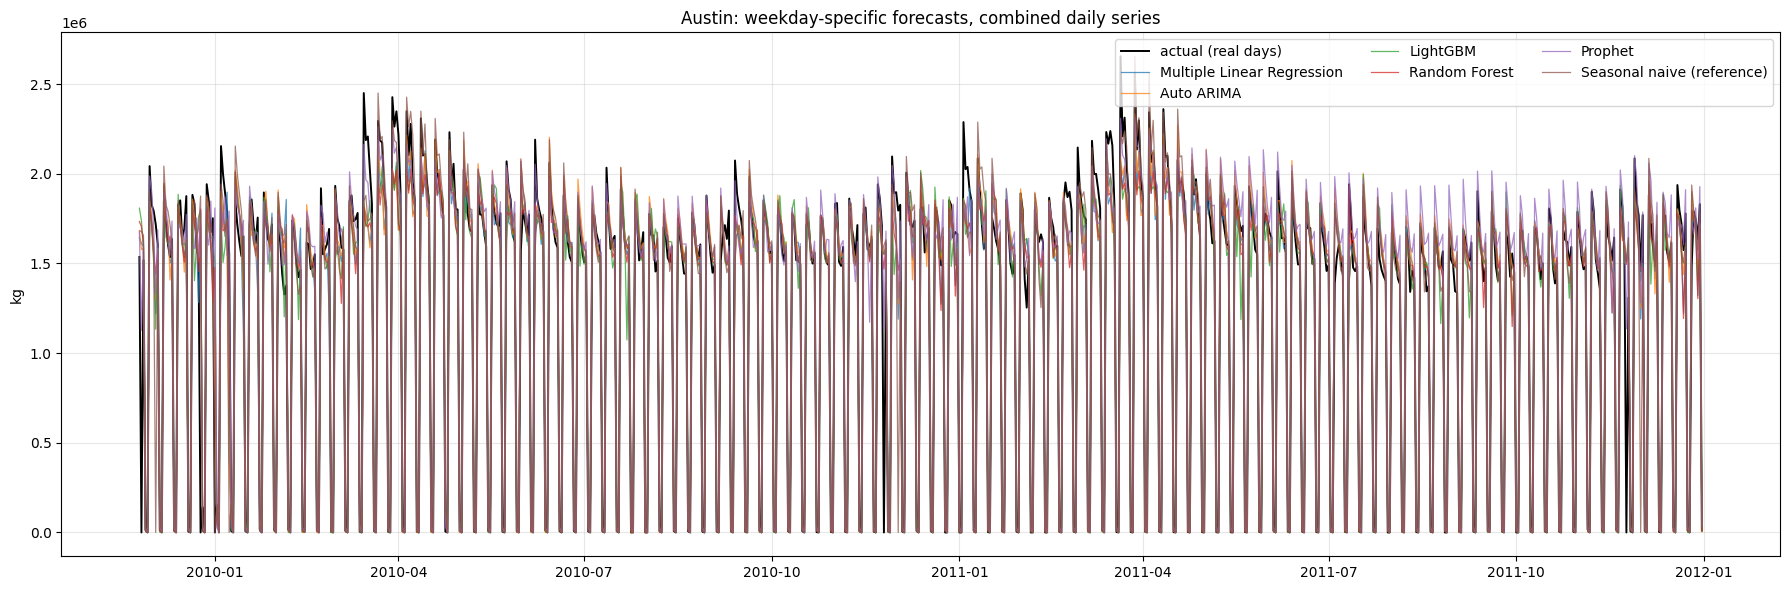

In [18]:
for dataset in data:
    keys = [k for k in all_combined if k[0] == dataset]
    if not keys:
        continue
    fig, ax = plt.subplots(figsize=(18, 6))
    first = all_combined[keys[0]]
    ax.plot(first.index, first["actual"].where(first["scored"]), color="black", lw=1.4, label="actual (real days)")
    for _, model_name in keys:
        r = all_combined[(dataset, model_name)]
        ax.plot(r.index, r["predicted"], lw=0.9, alpha=0.75, label=model_name)
    ax.set_title(f"{dataset}: weekday-specific forecasts, combined daily series"); ax.set_ylabel("kg")
    ax.legend(ncol=3); ax.grid(alpha=0.3); fig.tight_layout()
    fig.savefig(os.path.join(OUTPUT_DIR, safe_name(dataset), "plot_all_models.png"), dpi=120)
    plt.show()